In [78]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla

In [79]:
#Boundary conditions
Utop, Ubottom, Vtop, Vbottom = 0,0,-3.5,-3.5

In [80]:
U_an = lambda x, y: np.sin(2*np.pi*x)*np.sin(2*np.pi*y)
V_an = lambda x, y: -3.5 + np.cos(2*np.pi*x)*(np.cos(2*np.pi*y) - 1)
P_an = lambda x, y: np.sin(2*np.pi*y)*np.cos(2*np.pi*x)

In [81]:
# Forcing functions
f = lambda x, y: (2 * np.pi - 8 * np.pi ** 2) * np.sin(2 * np.pi * x) * np.sin(2 * np.pi * y)
g = lambda x, y: 4*np.pi**2*np.cos(2*np.pi*x) - (8*np.pi**2 + 2*np.pi)*np.cos(2*np.pi*x)*np.cos(2*np.pi*y)

In [82]:
def lap_periodic(n, h):
    e = np.ones(n)
    A = sp.diags([e[:-1], -2*e, e[:-1]], [-1, 0, 1], format="lil")
    A[0, -1] = 1
    A[-1, 0] = 1
    return A.tocsc() / h**2

In [83]:
def lap_dirichlet_type1(n, h):
    e = np.ones(n)
    A = sp.diags([e[:-1], -2*e, e[:-1]], [-1, 0, 1], format="lil")
    return A.tocsc() / h**2

In [84]:
def lap_dirichlet_type2(n, h):
    e = np.ones(n)
    A = sp.diags([e[:-1], -2*e, e[:-1]], [-1, 0, 1], format="lil")
    A[0,0] = -3
    A[-1, -1] = -3
    return A.tocsc() / h**2

In [85]:
def D_x(n, h):
    D = sp.diags([-1.0, 1.0], [0, 1], shape=(n, n), format="lil")
    D[-1, 0] = 1.0
    return D.tocsc() / h

def D_y(n, h):
    D = sp.diags([-1.0, 1.0], [-1, 0], shape=(n, n-1), format="lil")
    return D.tocsc() / h

In [86]:
def solve(Nx, Ny):
    hx = 1.0 / Nx
    hy = 1.0 / Ny

    #Grid points
    xc = (np.arange(Nx) + 0.5) * hx
    yc = (np.arange(Ny) + 0.5) * hy
    xf = np.arange(Nx) * hx
    yf = np.arange(1, Ny) * hy
    XU, YU = np.meshgrid(xf, yc)
    XV, YV = np.meshgrid(xc, yf)
    XP, YP = np.meshgrid(xc, yc)

    Ix, Iy, Iyv = sp.identity(Nx), sp.identity(Ny), sp.identity(Ny-1)
    Lu = sp.kron(Iy,  lap_periodic(Nx, hx)) + sp.kron(lap_dirichlet_type2(Ny, hy), Ix)
    Lv = sp.kron(Iyv, lap_periodic(Nx, hx)) + sp.kron(lap_dirichlet_type1(Ny-1, hy), Ix)
    Dx = sp.kron(Iy, D_x(Nx, hx))
    Dy = sp.kron(D_y(Ny, hy), Ix)
    Gx = -Dx.T
    Gy = -Dy.T
    bcU = np.zeros((Ny, Nx));   bcU[0,:] = 2*Ubottom/hy**2; bcU[-1,:] = 2*Utop/hy**2
    bcV = np.zeros((Ny-1, Nx)); bcV[0,:] = Vbottom/hy**2;   bcV[-1,:] = Vtop/hy**2
    hbc = np.zeros((Ny, Nx));   hbc[0,:] = Vbottom/hy;      hbc[-1,:] = -Vtop/hy

    rhs = np.concatenate([(f(XU, YU) - bcU).ravel(),
                      (g(XV, YV) - bcV).ravel(),
                      hbc.ravel()])

    nU, nV, nP = Nx*Ny, Nx*(Ny-1), Nx*Ny
    A = sp.bmat([[Lu, None, -Gx], [None, Lv, -Gy], [Dx, Dy, None]], format="csr")
    c = sp.csc_matrix(np.r_[np.zeros(nU + nV), np.ones(nP)])
    A_b = sp.bmat([[A, c.T], [c, None]], format="csc")
    sol = spla.spsolve(A_b, np.r_[rhs, 0.0])
    U = sol[:nU].reshape(Ny, Nx)
    V = sol[nU:nU+nV].reshape(Ny-1, Nx)
    P = sol[nU+nV:nU+nV+nP].reshape(Ny, Nx)
    grids = dict(XU=XU, YU=YU, XV=XV, YV=YV, XP=XP, YP=YP)

    return U, V, P, grids



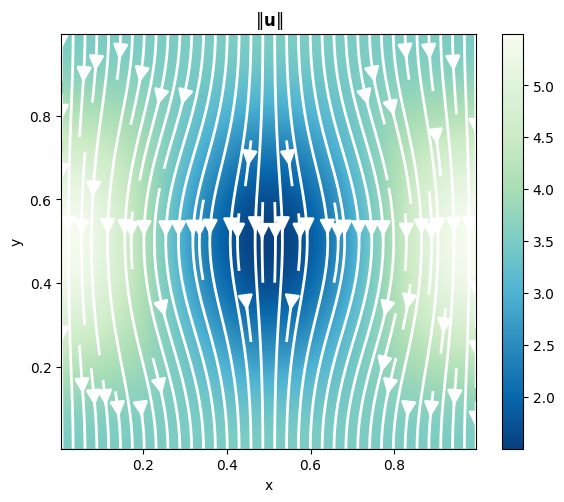

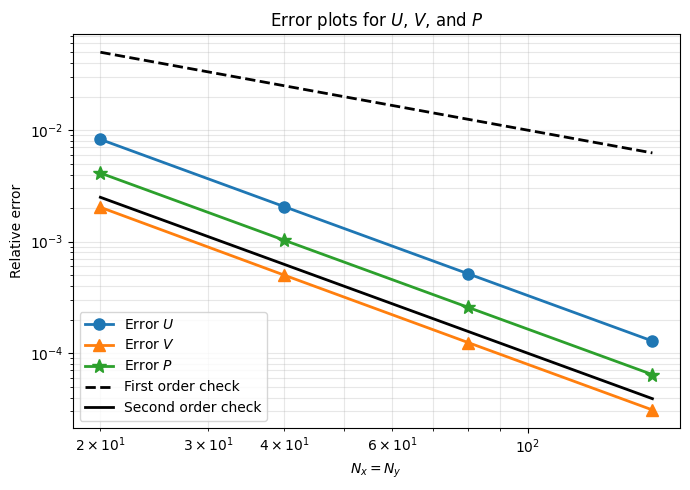

In [89]:
N = [20, 40, 80, 160]
err_U, err_V, err_P = [], [], []
for n in N:
    U, V, P, grids = solve(n, n)
    XU, YU, XV, YV, XP, YP = grids['XU'], grids['YU'], grids['XV'], grids['YV'], grids['XP'], grids['YP']
    err_U.append(np.linalg.norm(U - U_an(XU, YU)) / np.linalg.norm(U_an(XU, YU)))
    err_V.append(np.linalg.norm(V - V_an(XV, YV)) / np.linalg.norm(V_an(XV, YV)))
    err_P.append(np.linalg.norm(P - P_an(XP, YP)) / np.linalg.norm(P_an(XP, YP)))

n = N[-1]
Vbot, Vtop = -3.5, -3.5

Uc = 0.5 * (U + np.roll(U, -1, axis=1))
Vfull = np.vstack([np.full((1, n), Vbot), V, np.full((1, n), Vtop)])
Vc = 0.5 * (Vfull[:-1] + Vfull[1:])
speed = np.sqrt(Uc**2 + Vc**2)

xc, yc = grids["XP"][0, :], grids["YP"][:, 0]

fig, ax = plt.subplots(figsize=(6, 5))
pc = ax.pcolormesh(xc, yc, speed, shading="gouraud", cmap="mako" if "mako" in plt.colormaps() else "GnBu_r")
ax.streamplot(xc, yc, Uc, Vc, color="white", density=1.2, linewidth=2, arrowsize=2.2)
fig.colorbar(pc, ax=ax)
ax.set(xlabel="x", ylabel="y", title=r"$\|\mathbf{u}\|$", aspect="equal",
       xlim=(xc[0], xc[-1]), ylim=(yc[0], yc[-1]))
fig.tight_layout()
fig.savefig("../writeup/figs/problem1.png", dpi=150)

N = np.asarray(N) 

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(N, err_U, "o-", label="Error $U$", linewidth=2, markersize=8)
ax.loglog(N, err_V, "^-", label="Error $V$", linewidth=2, markersize=8)
ax.loglog(N, err_P, "*-", markersize=10, label="Error $P$", linewidth=2)
ax.loglog(N, 1/N,    "k--", label="First order check", linewidth=2)
ax.loglog(N, 1/N**2, "k-",  label="Second order check", linewidth=2)

ax.set_xlabel("$N_x = N_y$")
ax.set_ylabel("Relative error")
ax.set_title("Error plots for $U$, $V$, and $P$")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()